In [1]:
from pathlib import Path
import random
import numpy as np, matplotlib.pyplot as plt, torch
from ultralytics import YOLO

In [2]:
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATASET_DIR = ROOT / 'data/processed/fpb_myfoodrepo_full'
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'

BASELINE_W = next((ROOT / 'models').glob('food_yolo11n_2*')) / 'best.pt'
AUG_DIR = next((ROOT / 'models').glob('food_yolo11n_aug_*'))
MODELS = {
    'baseline': YOLO(str(BASELINE_W)),
    'aug_geo':  YOLO(str(AUG_DIR / 'aug_geo_best.pt')),
}
print({k: Path(m.ckpt_path).name for k, m in MODELS.items()})

{'baseline': 'best.pt', 'aug_geo': 'aug_geo_best.pt'}


In [3]:
def read_list(txt):
    paths = []
    for line in Path(txt).read_text().splitlines():
        line = line.strip()
        if line:
            p = Path(line)
            paths.append(p if p.is_absolute() else DATASET_DIR / p)
    return paths

test_images = read_list(DATASET_DIR / 'test.txt')
names = MODELS['baseline'].names

def gt_classes(img_path):
    lbl = Path(str(img_path).replace('/images/', '/labels/')).with_suffix('.txt')
    if not lbl.exists():
        return []
    return sorted({names[int(l.split()[0])] for l in lbl.read_text().splitlines() if l.strip()})

print('Тестовых изображений:', len(test_images))

Тестовых изображений: 3272



myfoodrepo__9f574775baeec6b4ac4f2c93.jpg | разметка: water
  baseline  water 0.99
  aug_geo   water 0.85

myfoodrepo__18b2b105754eac4f97ec2d61.jpg | разметка: bread_white
  baseline  bread_white 0.14, water 0.08
  aug_geo   water 0.11

myfoodrepo__627de7d1ed32595b6e5d569d.jpg | разметка: chickpeas, mixed_vegetables, tofu
  baseline  ничего не найдено
  aug_geo   ничего не найдено

myfoodrepo__5a3f35c11b0efaa7d5b975f3.jpg | разметка: bread_white, butter
  baseline  water 0.09
  aug_geo   ничего не найдено

fpb__52e33326dbedb69bf44301d6.jpg | разметка: manpar
  baseline  ничего не найдено
  aug_geo   ничего не найдено

fpb__e221bd3e7d37d67e1e554f2e.jpg | разметка: kirieshki_cheese, pop_corn, rollton, tuc
  baseline  white_coffee 0.53, leaf_spinach 0.31, apple_strudel 0.24
  aug_geo   burger 0.17, water 0.09, hard_cheese 0.06


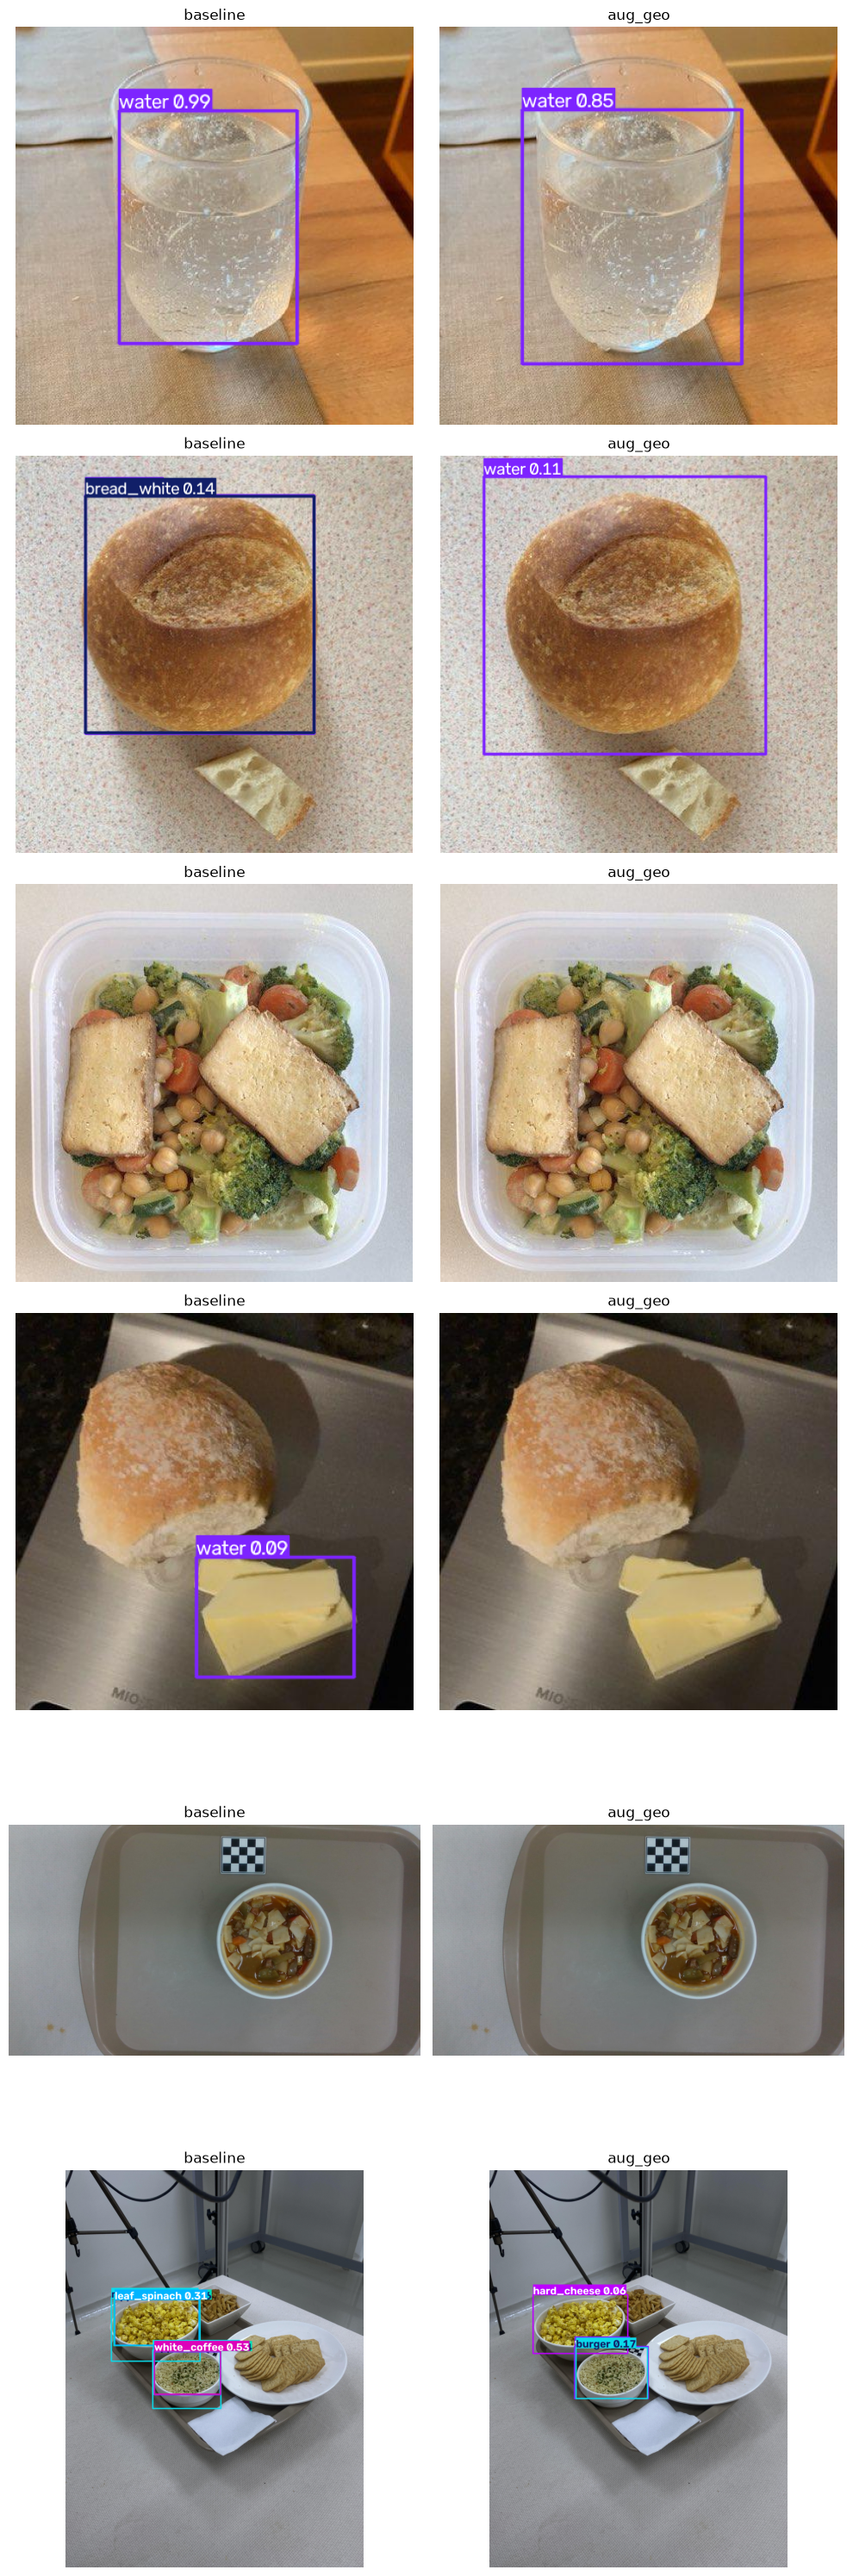

In [4]:
random.seed(7)
sample = random.sample(test_images, 6)

fig, axes = plt.subplots(len(sample), 2, figsize=(10, 5 * len(sample)))
for row, img_path in enumerate(sample):
    print(f'\n{img_path.name} | разметка: {", ".join(gt_classes(img_path)) or "—"}')
    for col, (variant, model) in enumerate(MODELS.items()):
        r = model.predict(str(img_path), imgsz=640, conf=0.05, device=DEVICE, verbose=False)[0]
        axes[row, col].imshow(r.plot()[:, :, ::-1])          # BGR -> RGB
        axes[row, col].set_title(variant); axes[row, col].axis('off')
        top = sorted(zip(r.boxes.conf.tolist(), r.boxes.cls.int().tolist()), reverse=True)[:3]
        print(f'  {variant:9s}', ', '.join(f'{names[c]} {p:.2f}' for p, c in top) or 'ничего не найдено')
plt.tight_layout(); plt.show()